# Solutions · 15 · Project: runaway in a tubular reactor

Worked solutions to the exercises of [notebook 15](../notebooks/15_project_runaway_in_a_tubular_reactor.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize as sopt
from engmolines import problems as pr, integrators as ti, linalg as la, datasets
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

In [2]:
data = pd.read_csv(datasets.path("reactor_profiles.csv"), comment="#")
data = data[data.T_K > 0].reset_index(drop=True)
R, T_ref = 8.314, 320.0
x_tc = np.linspace(0, 2, 11)

def profile(T_in, k0, E, n=60):
    pm = pr.tubular_reactor(n=n, T_in=T_in, k0=k0, E=E)
    sm = pm.solve("bdf", 0.5, order=2, n_out=1)
    return np.interp(x_tc, pm.x, sm.y[-1][pm.n // 2 :])

def fit(runs):
    def residuals(theta):
        k0 = np.exp(theta[0] + theta[1] / (R * T_ref))
        res = []
        for T_in, grp in runs.groupby("T_in_K"):
            res.append(np.interp(grp.x_m, x_tc, profile(T_in, k0, theta[1])) - grp.T_K.to_numpy())
        return np.concatenate(res)
    f = sopt.least_squares(residuals, [np.log(5e7 * np.exp(-60e3 / (R * T_ref)) * 1.5), 55e3], diff_step=[1e-3, 1e-3], xtol=1e-8)
    J, r_ = f.jac, f.fun
    cov = (r_ @ r_) / max(len(r_) - 2, 1) * np.linalg.inv(J.T @ J)
    return f.x, np.sqrt(np.diag(cov))

def ignition(k0, E, hw=0.1):
    T_ins = np.arange(300.0, 346.0, 2.5)
    rises = np.array([pr.tubular_reactor(n=60, T_in=T, k0=k0, E=E, hw=hw).solve("bdf", 0.5, order=2, n_out=1).y[-1][61:].max() - T for T in T_ins])
    return T_ins[np.argmax(np.gradient(rises, T_ins))]

## Exercise 1

Repeat the fit with only the 310 and 320 K profiles. How do the standard errors and the predicted ignition temperature change? Then add a (synthetic) 335 K profile generated with the true parameters: what does a near-critical measurement do to the fit?

In [3]:
for label, runs in (("310 and 320 K only", data[data.T_in_K < 325]), ("all three", data)):
    theta, se = fit(runs)
    k0 = np.exp(theta[0] + theta[1] / (R * T_ref))
    print(f"{label:<18}: k(320) = {np.exp(theta[0]):.3e} (+/- {100 * se[0]:.1f} %), E = {theta[1] / 1e3:.1f} +/- {se[1] / 1e3:.1f} kJ/mol; ignition at {ignition(k0, theta[1]):.1f} K")
rng = np.random.default_rng(1)
syn = profile(335.0, 5e7, 60e3) + rng.normal(0, 0.5, 11)
extra = pd.DataFrame({"T_in_K": 335.0, "thermocouple": np.arange(1, 12), "x_m": x_tc, "T_K": syn})
theta, se = fit(pd.concat([data, extra], ignore_index=True))
k0 = np.exp(theta[0] + theta[1] / (R * T_ref))
print(f"{'with a 335 K run':<18}: k(320) = {np.exp(theta[0]):.3e} (+/- {100 * se[0]:.1f} %), E = {theta[1] / 1e3:.1f} +/- {se[1] / 1e3:.1f} kJ/mol; ignition at {ignition(k0, theta[1]):.1f} K")

310 and 320 K only: k(320) = 7.993e-03 (+/- 2.0 %), E = 58.5 +/- 3.5 kJ/mol; ignition at 335.0 K


all three         : k(320) = 7.965e-03 (+/- 2.0 %), E = 60.5 +/- 0.9 kJ/mol; ignition at 335.0 K


with a 335 K run  : k(320) = 8.074e-03 (+/- 0.8 %), E = 59.9 +/- 0.2 kJ/mol; ignition at 335.0 K


With only the two coolest runs the activation energy is poorly determined (the hot-spot rises are 3 and 8 K,
little above the noise) and the predicted ignition temperature is less certain. A run near the critical
point carries far more information - the hot spot there is exquisitely sensitive to the kinetics - and
tightens both parameters; it is also, of course, the run a plant would least like to perform.

## Exercise 2

The runaway boundary depends on the wall coefficient h_w. Map the ignition temperature as a function of h_w from 0.05 to 0.3 1/s (a runaway diagram) with the fitted kinetics.

 h_w (1/s)  ignition T_in (K)
      0.05              332.5
      0.10              335.0
      0.20              340.0
      0.30              345.0


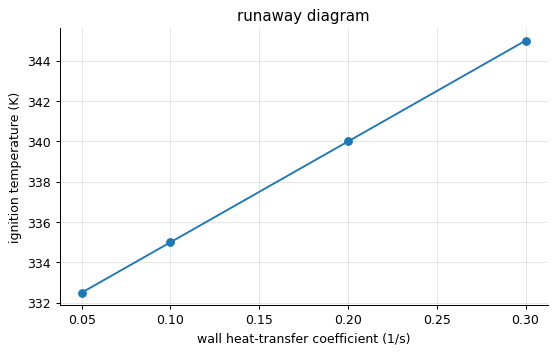

In [4]:
theta, se = fit(data)
k0, E = np.exp(theta[0] + theta[1] / (R * T_ref)), theta[1]
hws = np.array([0.05, 0.1, 0.2, 0.3])
T_ign = [ignition(k0, E, hw) for hw in hws]
print(pd.DataFrame({"h_w (1/s)": hws, "ignition T_in (K)": T_ign}).to_string(index=False))
plt.plot(hws, T_ign, "o-"); plt.xlabel("wall heat-transfer coefficient (1/s)"); plt.ylabel("ignition temperature (K)"); plt.title("runaway diagram"); plt.show()

Better cooling raises the ignition temperature: the runaway diagram is the operating map the fitted kinetics
provide. Its slope - a few kelvin per 0.1 s⁻¹ here - says how much a fouled wall (lower h_w) narrows the safe
window.

## Exercise 3

**Implement it yourself:** replace the steady-state-by-transient with a direct Newton solve of the steady equations rhs(y) = 0 (use `linalg.banded_jacobian` and `linalg.solve_banded`) started from the transient's state at t = 20 s, and compare the cost with integrating to t = 80 s.

In [5]:
p = pr.tubular_reactor(n=100, T_in=330.0)
s20 = p.solve("bdf", 0.5, order=2, t_end=20.0, n_out=1)
y = s20.y[-1].copy()
f = lambda v: p.rhs(0.0, v)   # noqa: E731
evals = 0
for k in range(20):
    Jb = la.banded_jacobian(f, y, *p.band); evals += p.band[0] + p.band[1] + 2
    fact, piv = la.lu_banded(Jb, *p.band)
    dy = la.lu_banded_solve(fact, piv, -f(y)); y += dy
    if np.max(np.abs(dy)) < 1e-10 * np.max(np.abs(y)):
        break
s80 = p.solve("bdf", 0.5, order=2, n_out=1)
print(f"Newton on rhs(y) = 0 from the t = 20 s state: {k + 1} iterations, {evals} function evaluations; differs from the t = 80 s transient by {np.max(np.abs(y - s80.y[-1])):.1e} K")
print(f"the transient to 80 s cost {s80.newton_iterations} Newton iterations (each a banded solve) and {s80.steps} steps")

Newton on rhs(y) = 0 from the t = 20 s state: 3 iterations, 618 function evaluations; differs from the t = 80 s transient by 6.3e-13 K
the transient to 80 s cost 435 Newton iterations (each a banded solve) and 160 steps


A direct Newton solve of the steady equations converges in a handful of iterations from a reasonable start
(the transient at 20 s), each iteration one coloured Jacobian and one banded solve - several times cheaper
than integrating to 80 s. The transient is still the right tool when the start is poor (Newton on the steady
reactor equations has multiple solutions near ignition) or when the dynamics themselves matter.